<a href="https://colab.research.google.com/github/rahafjafar/Normal-3-Hour-Ahead-Consumption-Forecasting-Model/blob/main/02_jo3_3h_consumption_forecasting_model_copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Normal 3-Hour Ahead Consumption Forecasting Model

This notebook is based on the previous normal-consumption forecasting notebook, with two main modifications:

1. The target is changed from **next-hour consumption** to **next 6-hour total consumption**.
2. Weekly Jordan-style refill-cycle features are added.

## Main target

Instead of predicting one hourly reading:

`actual_consumption`

we predict:

`target_next_3h_total_consumption`

which means:

`actual_consumption(t+1) + actual_consumption(t+2) + ... + actual_consumption(t+6)`

## Why this is useful

A 6-hour forecast is more useful for planning and usually more stable than predicting a single noisy hourly value.

## Leakage rule

We still avoid using leakage features such as:

- `flow_rate`
- `water_level_change`
- `anomaly_flag`
- `leak_flag`
- `anomaly_type`
- future actual values as model inputs

The future values are used only to create the target.

In [ ]:
# ============================================================
# CELL 1 — Import Libraries
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except Exception as e:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not available. Install it using: pip install xgboost")
    print("Reason:", e)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")
print("XGBoost available:", XGBOOST_AVAILABLE)

Libraries imported successfully.
XGBoost available: True


## 1. Load clean master dataset

In [ ]:
# ============================================================
# CELL 2 — Load Clean Dataset
# ============================================================

DATA_PATH = "processed_data/clean_master_dataset_jordan.csv"

if not os.path.exists(DATA_PATH):
    possible_paths = [
        "../processed_data/clean_master_dataset_jordan.csv",
        "../processed_data/clean_master_dataset.csv",
        "../data/clean_master_dataset_jordan.csv",
        "../data/water_consumption_jordan_realistic.csv",
        "clean_master_dataset_jordan.csv"
    ]

    for path in possible_paths:
        if os.path.exists(path):
            DATA_PATH = path
            break

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Path:", DATA_PATH)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Path: processed_data/clean_master_dataset_jordan.csv
Shape: (216000, 39)


,household_id,timestamp,hour,day_of_week,is_weekend,month,season,temperature,building_type,number_of_users,behavior_profile,tank_capacity,num_of_tanks,total_tank_capacity,previous_consumption,actual_consumption,flow_rate,water_level,water_level_change,tank_emptied_flag,sensor_status,anomaly_flag,leak_flag,anomaly_type,rolling_avg_consumption,consumption_pattern_score,time_since_last_usage,day,date,week_of_year,consumption_change,water_level_diff,diff_from_rolling_avg,high_consumption_flag,day_of_week_num,hour_sin,hour_cos,day_sin,day_cos
0,H001,2025-01-01 00:00:00,0,Wednesday,0,1,Winter,13.27,Apartment,3,Irregular,1800,2,3600,17.38,17.38,1.14,3582.62,0.00,0,normal,0,0,normal,17.38,0.00,0,1,2025-01-01,1,0.00,0.00,0.00,0,2,0.000000,1.000000,0.974928,-0.222521
1,H001,2025-01-01 01:00:00,1,Wednesday,0,1,Winter,9.46,Apartment,3,Irregular,1800,2,3600,17.38,14.57,0.93,3568.05,14.57,0,normal,0,0,normal,15.98,12.43,0,1,2025-01-01,1,-2.81,-14.57,-1.41,0,2,0.258819,0.965926,0.974928,-0.222521
2,H001,2025-01-01 02:00:00,2,Wednesday,0,1,Winter,12.18,Apartment,3,Irregular,1800,2,3600,14.57,13.12,1.50,3554.93,13.12,0,normal,0,0,normal,15.02,14.42,0,1,2025-01-01,1,-1.45,-13.12,-1.90,0,2,0.500000,0.866025,0.974928,-0.222521
3,H001,2025-01-01 03:00:00,3,Wednesday,0,1,Winter,17.87,Apartment,3,Irregular,1800,2,3600,13.12,20.05,1.73,3534.88,20.05,0,normal,0,0,normal,16.28,18.88,0,1,2025-01-01,1,6.93,-20.05,3.77,0,2,0.707107,0.707107,0.974928,-0.222521
4,H001,2025-01-01 04:00:00,4,Wednesday,0,1,Winter,9.18,Apartment,3,Irregular,1800,2,3600,20.05,10.26,1.12,3524.62,10.26,0,normal,0,0,normal,15.08,25.10,0,1,2025-01-01,1,-9.79,-10.26,-4.82,0,2,0.866025,0.500000,0.974928,-0.222521


In [ ]:
# ============================================================
# CELL 3 — Convert Timestamp and Sort Data
# ============================================================

df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values(
    by=["household_id", "timestamp"]
).reset_index(drop=True)

print("Timestamp converted successfully.")
print("Data sorted by household_id and timestamp.")

display(df[["household_id", "timestamp", "actual_consumption", "anomaly_type"]].head())

Timestamp converted successfully.
Data sorted by household_id and timestamp.


,household_id,timestamp,actual_consumption,anomaly_type
0,H001,2025-01-01 00:00:00,17.38,normal
1,H001,2025-01-01 01:00:00,14.57,normal
2,H001,2025-01-01 02:00:00,13.12,normal
3,H001,2025-01-01 03:00:00,20.05,normal
4,H001,2025-01-01 04:00:00,10.26,normal


## 2. Create 3-Hour Ahead Target

The target is the total consumption for the next 3 hours.

Important:

- The model does **not** receive these future values as features.
- Future values are used only to create the supervised learning target.
- To keep the model focused on expected normal behavior, we train only on rows where:
  - current reading is normal
  - the next 3 hours are also normal

In [ ]:
# ============================================================
# CELL 4 — Create 3-Hour Ahead Target
# ============================================================

FORECAST_HORIZON = 3

df_all_records = df.copy()

# Create future consumption columns and future anomaly indicators
future_consumption_cols = []

for step in range(1, FORECAST_HORIZON + 1):
    col_name = f"future_consumption_t_plus_{step}h"

    df[col_name] = (
        df.groupby("household_id")["actual_consumption"]
        .shift(-step)
    )

    future_consumption_cols.append(col_name)

    df[f"future_anomaly_type_t_plus_{step}h"] = (
        df.groupby("household_id")["anomaly_type"]
        .shift(-step)
    )

df["target_next_3h_total_consumption"] = df[future_consumption_cols].sum(axis=1)

# Keep rows where the current reading and all next 3 readings are normal
future_normal_conditions = []

for step in range(1, FORECAST_HORIZON + 1):
    future_normal_conditions.append(
        df[f"future_anomaly_type_t_plus_{step}h"] == "normal"
    )

df["future_3h_all_normal"] = np.logical_and.reduce(future_normal_conditions)

print("3-hour target created successfully.")
print("Target column: target_next_3h_total_consumption")

display(df[[
    "household_id",
    "timestamp",
    "anomaly_type",
    "actual_consumption",
    "target_next_3h_total_consumption",
    "future_3h_all_normal"
]].head(10))

3-hour target created successfully.
Target column: target_next_3h_total_consumption


,household_id,timestamp,anomaly_type,actual_consumption,target_next_3h_total_consumption,future_3h_all_normal
0,H001,2025-01-01 00:00:00,normal,17.38,47.74,True
1,H001,2025-01-01 01:00:00,normal,14.57,43.43,True
2,H001,2025-01-01 02:00:00,normal,13.12,65.32,False
3,H001,2025-01-01 03:00:00,normal,20.05,72.47,False
4,H001,2025-01-01 04:00:00,normal,10.26,116.91,False
5,H001,2025-01-01 05:00:00,abnormal_spike,35.01,129.38,True
6,H001,2025-01-01 06:00:00,normal,27.20,116.47,True
7,H001,2025-01-01 07:00:00,normal,54.70,76.62,True
8,H001,2025-01-01 08:00:00,normal,47.48,63.13,True
9,H001,2025-01-01 09:00:00,normal,14.29,71.02,True


In [ ]:
# ============================================================
# CELL 5 — Filter to Normal Current and Normal Future Horizon
# ============================================================

print("Before filtering:")
display(df["anomaly_type"].value_counts())

original_shape = df.shape

df = df[
    (df["anomaly_type"] == "normal") &
    (df["future_3h_all_normal"] == True)
].copy()

# Drop rows where target could not be created because of end-of-series horizon
df = df.dropna(subset=["target_next_3h_total_consumption"]).copy()

df = df.sort_values(
    by=["household_id", "timestamp"]
).reset_index(drop=True)

print("\nOriginal shape:", original_shape)
print("After filtering shape:", df.shape)
print("\nAfter filtering:")
display(df["anomaly_type"].value_counts())

print("\nRemaining households:", df["household_id"].nunique())
display(df["target_next_3h_total_consumption"].describe())

Before filtering:


anomaly_type
normal            197733
scarcity            7468
leak                4825
abnormal_spike      3855
sensor_fault        2119
Name: count, dtype: int64


Original shape: (216000, 47)
After filtering shape: (168264, 47)

After filtering:


anomaly_type
normal    168264
Name: count, dtype: int64


Remaining households: 50


count    168264.000000
mean        105.364711
std          56.758753
min           2.810000
25%          62.120000
50%          92.700000
75%         138.270000
max         442.530000
Name: target_next_3h_total_consumption, dtype: float64

In [ ]:
# ============================================================
# CELL 6 — Data Quality Check After Filtering
# ============================================================

print("Shape:", df.shape)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(20))

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget summary:")
display(df["target_next_3h_total_consumption"].describe())

Shape: (168264, 47)

Missing values:


household_id            0
timestamp               0
hour                    0
day_of_week             0
is_weekend              0
month                   0
season                  0
temperature             0
building_type           0
number_of_users         0
behavior_profile        0
tank_capacity           0
num_of_tanks            0
total_tank_capacity     0
previous_consumption    0
actual_consumption      0
flow_rate               0
water_level             0
water_level_change      0
tank_emptied_flag       0
dtype: int64


Duplicate rows:
0

Target summary:


count    168264.000000
mean        105.364711
std          56.758753
min           2.810000
25%          62.120000
50%          92.700000
75%         138.270000
max         442.530000
Name: target_next_3h_total_consumption, dtype: float64

## 3. Safe Feature Engineering

We create features available at prediction time.

This version adds Jordan weekly refill-cycle features.

In [ ]:
# ============================================================
# CELL 7 — Safe Time Features
# ============================================================

df["day_of_week_num"] = df["timestamp"].dt.dayofweek
df["day"] = df["timestamp"].dt.day
df["week_of_year"] = df["timestamp"].dt.isocalendar().week.astype(int)

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["day_sin"] = np.sin(2 * np.pi * df["day_of_week_num"] / 7)
df["day_cos"] = np.cos(2 * np.pi * df["day_of_week_num"] / 7)

print("Safe time features created.")
display(df[["timestamp", "hour", "hour_sin", "hour_cos", "day_of_week_num", "day_sin", "day_cos"]].head())

Safe time features created.


,timestamp,hour,hour_sin,hour_cos,day_of_week_num,day_sin,day_cos
0,2025-01-01 00:00:00,0,0.000000,1.000000e+00,2,0.974928,-0.222521
1,2025-01-01 01:00:00,1,0.258819,9.659258e-01,2,0.974928,-0.222521
2,2025-01-01 06:00:00,6,1.000000,6.123234e-17,2,0.974928,-0.222521
3,2025-01-01 07:00:00,7,0.965926,-2.588190e-01,2,0.974928,-0.222521
4,2025-01-01 08:00:00,8,0.866025,-5.000000e-01,2,0.974928,-0.222521


In [ ]:
# ============================================================
# CELL 8 — Weekly Refill Cycle Features
# ============================================================

# Assumption:
# In Jordan, household water tanks are commonly refilled on a weekly cycle.
# We encode the household's position inside a 168-hour refill cycle.

df["hour_index_per_household"] = (
    df.groupby("household_id")
    .cumcount()
)

df["hours_since_refill"] = df["hour_index_per_household"] % (7 * 24)

df["hours_until_refill"] = (
    (7 * 24) - df["hours_since_refill"]
) % (7 * 24)

df["days_since_refill"] = (df["hours_since_refill"] // 24).astype(int)

df["refill_position"] = df["hours_since_refill"] / (7 * 24 - 1)

df["is_refill_day"] = (df["days_since_refill"] == 0).astype(int)

# Cyclic representation for weekly refill cycle
df["refill_sin"] = np.sin(2 * np.pi * df["hours_since_refill"] / (7 * 24))
df["refill_cos"] = np.cos(2 * np.pi * df["hours_since_refill"] / (7 * 24))

print("Weekly refill-cycle features created.")

display(df[[
    "household_id",
    "timestamp",
    "hours_since_refill",
    "hours_until_refill",
    "days_since_refill",
    "refill_position",
    "is_refill_day",
    "refill_sin",
    "refill_cos"
]].head(30))

Weekly refill-cycle features created.


,household_id,timestamp,hours_since_refill,hours_until_refill,days_since_refill,refill_position,is_refill_day,refill_sin,refill_cos
0,H001,2025-01-01 00:00:00,0,0,0,0.000000,1,0.000000,1.000000
1,H001,2025-01-01 01:00:00,1,167,0,0.005988,1,0.037391,0.999301
2,H001,2025-01-01 06:00:00,2,166,0,0.011976,1,0.074730,0.997204
3,H001,2025-01-01 07:00:00,3,165,0,0.017964,1,0.111964,0.993712
4,H001,2025-01-01 08:00:00,4,164,0,0.023952,1,0.149042,0.988831
5,H001,2025-01-01 09:00:00,5,163,0,0.029940,1,0.185912,0.982566
6,H001,2025-01-01 14:00:00,6,162,0,0.035928,1,0.222521,0.974928
7,H001,2025-01-01 15:00:00,7,161,0,0.041916,1,0.258819,0.965926
8,H001,2025-01-01 16:00:00,8,160,0,0.047904,1,0.294755,0.955573
9,H001,2025-01-01 17:00:00,9,159,0,0.053892,1,0.330279,0.943883


In [ ]:
# ============================================================
# CELL 9 — Safe Historical Lag and Rolling Features
# ============================================================

df["safe_previous_consumption"] = (
    df.groupby("household_id")["actual_consumption"]
    .shift(1)
)

df["safe_rolling_avg_7h"] = (
    df.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).mean())
)

df["safe_rolling_avg_24h"] = (
    df.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=24, min_periods=1).mean())
)

lag_hours = [1, 2, 3, 6, 12, 24, 48, 72, 168]

for lag in lag_hours:
    df[f"lag_{lag}h"] = (
        df.groupby("household_id")["actual_consumption"]
        .shift(lag)
    )

rolling_windows = [3, 6, 12, 24, 48, 168]

for window in rolling_windows:
    df[f"rolling_mean_{window}h"] = (
        df.groupby("household_id")["actual_consumption"]
        .transform(lambda s: s.shift(1).rolling(window=window, min_periods=1).mean())
    )

    df[f"rolling_std_{window}h"] = (
        df.groupby("household_id")["actual_consumption"]
        .transform(lambda s: s.shift(1).rolling(window=window, min_periods=2).std())
    )

# 6-hour recent momentum features
df["rolling_sum_6h"] = (
    df.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=6, min_periods=1).sum())
)

df["rolling_sum_12h"] = (
    df.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=12, min_periods=1).sum())
)

df["rolling_sum_24h"] = (
    df.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=24, min_periods=1).sum())
)

historical_cols = (
    ["safe_previous_consumption", "safe_rolling_avg_7h", "safe_rolling_avg_24h"] +
    [f"lag_{lag}h" for lag in lag_hours] +
    [f"rolling_mean_{w}h" for w in rolling_windows] +
    [f"rolling_std_{w}h" for w in rolling_windows] +
    ["rolling_sum_6h", "rolling_sum_12h", "rolling_sum_24h"]
)

for col in historical_cols:
    df[col] = df[col].fillna(df[col].median())

print("Safe historical features created.")
print("Historical feature count:", len(historical_cols))

display(df[[
    "household_id",
    "timestamp",
    "actual_consumption",
    "target_next_3h_total_consumption",
    "safe_previous_consumption",
    "lag_24h",
    "rolling_mean_24h",
    "rolling_mean_168h",
    "rolling_sum_6h"
]].head(10))

Safe historical features created.
Historical feature count: 27


,household_id,timestamp,actual_consumption,target_next_3h_total_consumption,safe_previous_consumption,lag_24h,rolling_mean_24h,rolling_mean_168h,rolling_sum_6h
0,H001,2025-01-01 00:00:00,17.38,47.74,30.59,30.56,30.602083,30.392143,184.75
1,H001,2025-01-01 01:00:00,14.57,43.43,17.38,30.56,17.380000,17.380000,17.38
2,H001,2025-01-01 06:00:00,27.20,116.47,14.57,30.56,15.975000,15.975000,31.95
3,H001,2025-01-01 07:00:00,54.70,76.62,27.20,30.56,19.716667,19.716667,59.15
4,H001,2025-01-01 08:00:00,47.48,63.13,54.70,30.56,28.462500,28.462500,113.85
5,H001,2025-01-01 09:00:00,14.29,71.02,47.48,30.56,32.266000,32.266000,161.33
6,H001,2025-01-01 14:00:00,19.47,59.67,14.29,30.56,29.270000,29.270000,175.62
7,H001,2025-01-01 15:00:00,22.44,69.57,19.47,30.56,27.870000,27.870000,177.71
8,H001,2025-01-01 16:00:00,19.18,72.54,22.44,30.56,27.191250,27.191250,185.58
9,H001,2025-01-01 17:00:00,18.05,85.96,19.18,30.56,26.301111,26.301111,177.56


## 4. Define features and target

In [ ]:
# ============================================================
# CELL 10 — Define Features and Target
# ============================================================

target = "target_next_3h_total_consumption"

base_features = [
    # Cyclic time features
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",

    # Calendar features
    "day",
    "week_of_year",
    "month",
    "is_weekend",

    # Weather
    "temperature",

    # Household information
    "number_of_users",
    "building_type",
    "behavior_profile",

    # Tank information
    "tank_capacity",
    "num_of_tanks",
    "total_tank_capacity",

    # Current non-leakage system state
    "water_level",

    # Weekly refill-cycle features
    "hours_since_refill",
    "hours_until_refill",
    "days_since_refill",
    "refill_position",
    "is_refill_day",
    "refill_sin",
    "refill_cos",
]

candidate_features = base_features + historical_cols
candidate_features = [col for col in candidate_features if col in df.columns]
candidate_features = list(dict.fromkeys(candidate_features))

categorical_features = [
    col for col in ["building_type", "behavior_profile"]
    if col in candidate_features
]

numerical_features = [
    col for col in candidate_features
    if col not in categorical_features
]

X = df[candidate_features]
y = df[target]

print("Target:", target)
print("Number of features:", len(candidate_features))
print("Categorical features:", categorical_features)
print("Numerical features:", len(numerical_features))

display(X.head())

Target: target_next_3h_total_consumption
Number of features: 50
Categorical features: ['building_type', 'behavior_profile']
Numerical features: 48


,hour_sin,hour_cos,day_sin,day_cos,day,week_of_year,month,is_weekend,temperature,number_of_users,building_type,behavior_profile,tank_capacity,num_of_tanks,total_tank_capacity,water_level,hours_since_refill,hours_until_refill,days_since_refill,refill_position,is_refill_day,refill_sin,refill_cos,safe_previous_consumption,safe_rolling_avg_7h,safe_rolling_avg_24h,lag_1h,lag_2h,lag_3h,lag_6h,lag_12h,lag_24h,lag_48h,lag_72h,lag_168h,rolling_mean_3h,rolling_mean_6h,rolling_mean_12h,rolling_mean_24h,rolling_mean_48h,rolling_mean_168h,rolling_std_3h,rolling_std_6h,rolling_std_12h,rolling_std_24h,rolling_std_48h,rolling_std_168h,rolling_sum_6h,rolling_sum_12h,rolling_sum_24h
0,0.000000,1.000000e+00,0.974928,-0.222521,1,1,1,0,13.27,3,Apartment,Irregular,1800,2,3600,3582.62,0,0,0,0.000000,1,0.000000,1.000000,30.59,30.812857,30.602083,30.59,30.58,30.58,30.58,30.58,30.56,30.51,30.49,30.39,30.920000,30.810000,30.774167,30.602083,30.497396,30.392143,7.568592,9.692990,10.808268,11.248129,11.490185,11.691714,184.75,368.705,731.62
1,0.258819,9.659258e-01,0.974928,-0.222521,1,1,1,0,9.46,3,Apartment,Irregular,1800,2,3600,3568.05,1,167,0,0.005988,1,0.037391,0.999301,17.38,17.380000,17.380000,17.38,30.58,30.58,30.58,30.58,30.56,30.51,30.49,30.39,17.380000,17.380000,17.380000,17.380000,17.380000,17.380000,7.568592,9.692990,10.808268,11.248129,11.490185,11.691714,17.38,17.380,17.38
2,1.000000,6.123234e-17,0.974928,-0.222521,1,1,1,0,12.86,3,Apartment,Irregular,1800,2,3600,3462.41,2,166,0,0.011976,1,0.074730,0.997204,14.57,15.975000,15.975000,14.57,17.38,30.58,30.58,30.58,30.56,30.51,30.49,30.39,15.975000,15.975000,15.975000,15.975000,15.975000,15.975000,1.986970,1.986970,1.986970,1.986970,1.986970,1.986970,31.95,31.950,31.95
3,0.965926,-2.588190e-01,0.974928,-0.222521,1,1,1,0,16.43,3,Apartment,Irregular,1800,2,3600,3407.71,3,165,0,0.017964,1,0.111964,0.993712,27.20,19.716667,19.716667,27.20,14.57,17.38,30.58,30.58,30.56,30.51,30.49,30.39,19.716667,19.716667,19.716667,19.716667,19.716667,19.716667,6.631307,6.631307,6.631307,6.631307,6.631307,6.631307,59.15,59.150,59.15
4,0.866025,-5.000000e-01,0.974928,-0.222521,1,1,1,0,8.43,3,Apartment,Irregular,1800,2,3600,3360.23,4,164,0,0.023952,1,0.149042,0.988831,54.70,28.462500,28.462500,54.70,27.20,14.57,30.58,30.58,30.56,30.51,30.49,30.39,32.156667,28.462500,28.462500,28.462500,28.462500,28.462500,20.519031,18.310504,18.310504,18.310504,18.310504,18.310504,113.85,113.850,113.85


## 5. Chronological Train / Validation / Test Split

In [ ]:
# ============================================================
# CELL 11 — Chronological Train / Validation / Test Split
# ============================================================

df = df.sort_values(["timestamp", "household_id"]).reset_index(drop=True)

train_end = df["timestamp"].quantile(0.60)
val_end = df["timestamp"].quantile(0.80)

train_df = df[df["timestamp"] <= train_end].copy()

val_df = df[
    (df["timestamp"] > train_end) &
    (df["timestamp"] <= val_end)
].copy()

test_df = df[df["timestamp"] > val_end].copy()

X_train = train_df[candidate_features]
y_train = train_df[target]

X_val = val_df[candidate_features]
y_val = val_df[target]

X_test = test_df[candidate_features]
y_test = test_df[target]

print("Train end:", train_end)
print("Validation end:", val_end)

print("\nTrain shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("\nTrain date range:", train_df["timestamp"].min(), "→", train_df["timestamp"].max())
print("Validation date range:", val_df["timestamp"].min(), "→", val_df["timestamp"].max())
print("Test date range:", test_df["timestamp"].min(), "→", test_df["timestamp"].max())

Train end: 2025-04-17 20:00:00
Validation end: 2025-05-23 22:00:00

Train shape: (100968, 50)
Validation shape: (33660, 50)
Test shape: (33636, 50)

Train date range: 2025-01-01 00:00:00 → 2025-04-17 20:00:00
Validation date range: 2025-04-17 21:00:00 → 2025-05-23 22:00:00
Test date range: 2025-05-23 23:00:00 → 2025-06-29 20:00:00


,split,records
0,Train,100968
1,Validation,33660
2,Test,33636


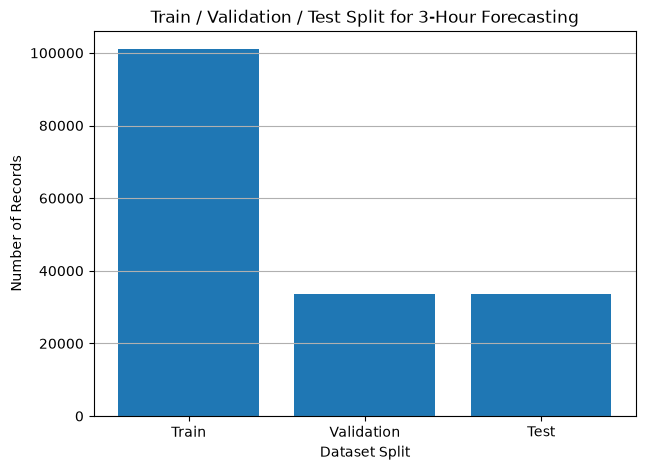

In [ ]:
# ============================================================
# CELL 12 — Visualize Split Sizes
# ============================================================

split_sizes = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "records": [len(train_df), len(val_df), len(test_df)]
})

display(split_sizes)

plt.figure(figsize=(7, 5))
plt.bar(split_sizes["split"], split_sizes["records"])
plt.title("Train / Validation / Test Split for 3-Hour Forecasting")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Records")
plt.grid(axis="y")
plt.show()

## 6. Preprocessing and model pipeline

In [ ]:
# ============================================================
# CELL 13 — Build Preprocessor
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [ ]:
# ============================================================
# CELL 14 — Evaluation Helper Functions
# ============================================================

def evaluate_predictions(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    smape = np.mean(
        2 * np.abs(y_pred - y_true) /
        (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    ) * 100

    return mae, rmse, smape, r2


def train_evaluate_pipeline(model_name, model):
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    val_pred = pipeline.predict(X_val)

    train_mae, train_rmse, train_smape, train_r2 = evaluate_predictions(y_train, train_pred)
    val_mae, val_rmse, val_smape, val_r2 = evaluate_predictions(y_val, val_pred)

    result = {
        "model": model_name,
        "train_MAE": train_mae,
        "train_RMSE": train_rmse,
        "train_SMAPE": train_smape,
        "train_R2": train_r2,
        "val_MAE": val_mae,
        "val_RMSE": val_rmse,
        "val_SMAPE": val_smape,
        "val_R2": val_r2
    }

    return pipeline, result

## 7. Baseline model comparison

In [ ]:
# ============================================================
# CELL 15 — Define Baseline Models
# ============================================================

models = {
    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(alpha=1.0),

    "Lasso": Lasso(alpha=0.001, max_iter=5000, random_state=RANDOM_STATE),

    "ElasticNet": ElasticNet(
        alpha=0.001,
        l1_ratio=0.5,
        max_iter=5000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        max_depth=22,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=700,
        max_leaf_nodes=31,
        l2_regularization=0.05,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=25,
        random_state=RANDOM_STATE
    )
}

if XGBOOST_AVAILABLE:
    models["XGBoost"] = XGBRegressor(
        n_estimators=700,
        max_depth=6,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

print("Models defined successfully.")
print(list(models.keys()))

Models defined successfully.
['Linear Regression', 'Ridge', 'Lasso', 'ElasticNet', 'Random Forest', 'Extra Trees', 'HistGradientBoosting', 'XGBoost']


In [ ]:
# ============================================================
# CELL 16 — Train and Evaluate Baseline Models
# ============================================================

baseline_results = []
baseline_pipelines = {}

for model_name, model in models.items():
    print("=" * 70)
    print("Training:", model_name)

    pipeline, result = train_evaluate_pipeline(model_name, model)

    baseline_results.append(result)
    baseline_pipelines[model_name] = pipeline

baseline_results_df = pd.DataFrame(baseline_results).sort_values(by="val_RMSE")

display(baseline_results_df)

Training: Linear Regression
Training: Ridge
Training: Lasso
Training: ElasticNet
Training: Random Forest
Training: Extra Trees
Training: HistGradientBoosting
Training: XGBoost


,model,train_MAE,train_RMSE,train_SMAPE,train_R2,val_MAE,val_RMSE,val_SMAPE,val_R2
7,XGBoost,9.549084,12.497799,10.640655,0.950594,11.137545,15.049043,11.851567,0.927736
6,HistGradientBoosting,9.843199,12.968531,10.892161,0.946803,11.191169,15.141994,11.919890,0.926841
5,Extra Trees,1.973198,2.937969,2.289158,0.997270,11.251618,15.210955,11.984837,0.926173
4,Random Forest,5.147608,6.956613,5.673176,0.984693,11.356870,15.356635,12.088664,0.924752
0,Linear Regression,18.004968,23.811725,19.267818,0.820655,17.983292,23.758154,19.279765,0.819894
1,Ridge,18.004907,23.811808,19.267549,0.820653,17.983450,23.758274,19.280241,0.819892
2,Lasso,18.006087,23.815851,19.267804,0.820592,17.982783,23.758584,19.280023,0.819887
3,ElasticNet,18.017989,23.829351,19.291510,0.820389,17.993687,23.768641,19.300736,0.819735


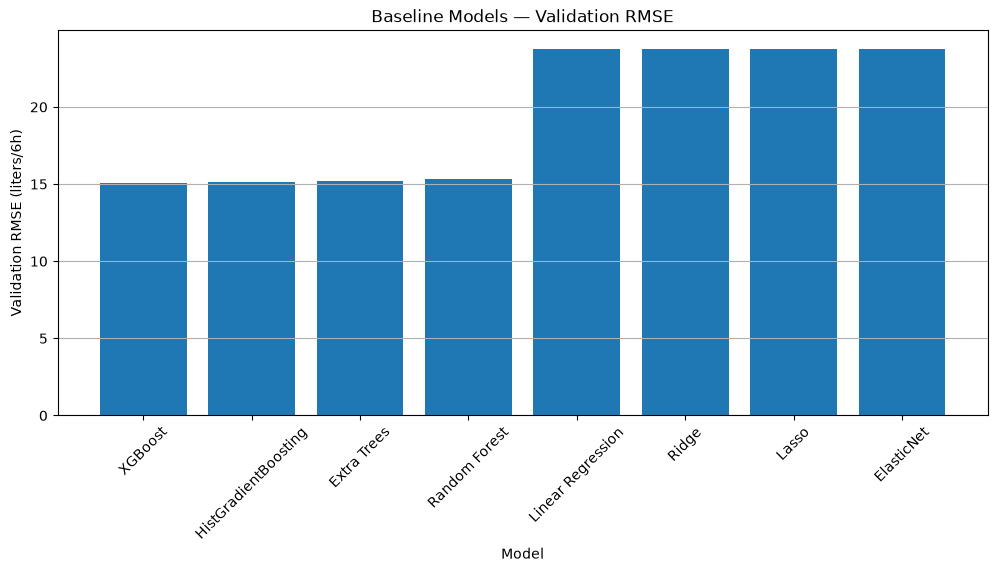

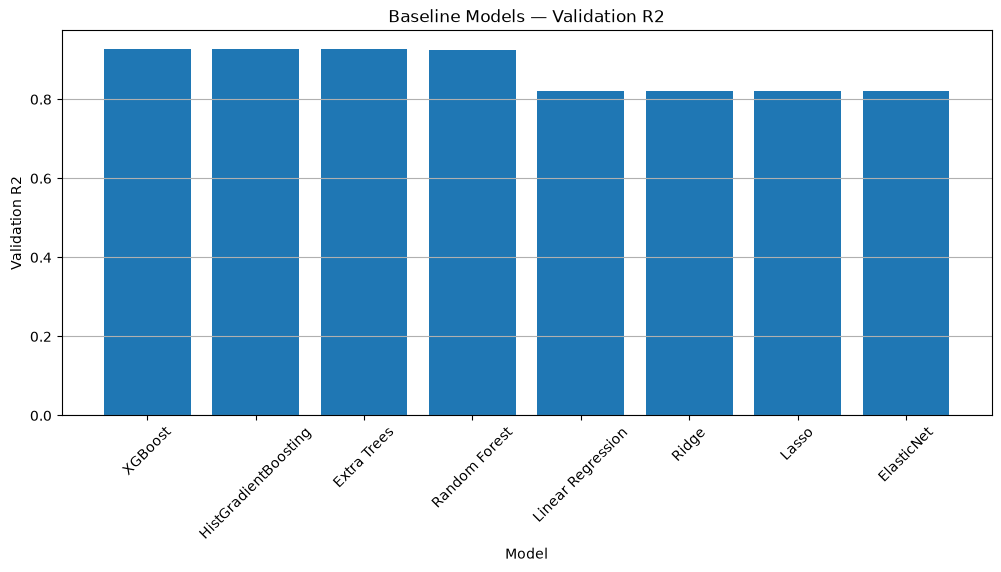

In [ ]:
# ============================================================
# CELL 17 — Visualize Baseline Model Results
# ============================================================

plt.figure(figsize=(12, 5))
plt.bar(baseline_results_df["model"], baseline_results_df["val_RMSE"])
plt.title("Baseline Models — Validation RMSE")
plt.xlabel("Model")
plt.ylabel("Validation RMSE (liters/6h)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(12, 5))
plt.bar(baseline_results_df["model"], baseline_results_df["val_R2"])
plt.title("Baseline Models — Validation R2")
plt.xlabel("Model")
plt.ylabel("Validation R2")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

## 8. Regularization experiment

In [ ]:
# ============================================================
# CELL 18 — Regularization Experiment
# ============================================================

l2_values = [0.0, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0]

regularization_results = []
regularization_pipelines = {}

for l2 in l2_values:
    print("Testing l2_regularization =", l2)

    model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=700,
        max_leaf_nodes=31,
        l2_regularization=l2,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=25,
        random_state=RANDOM_STATE
    )

    pipeline, result = train_evaluate_pipeline(f"HGB_l2_{l2}", model)
    result["l2_regularization"] = l2

    regularization_results.append(result)
    regularization_pipelines[result["model"]] = pipeline

regularization_df = pd.DataFrame(regularization_results).sort_values(by="val_RMSE")

display(regularization_df)

Testing l2_regularization = 0.0
Testing l2_regularization = 0.001
Testing l2_regularization = 0.01
Testing l2_regularization = 0.05
Testing l2_regularization = 0.1
Testing l2_regularization = 0.5
Testing l2_regularization = 1.0
Testing l2_regularization = 2.0


,model,train_MAE,train_RMSE,train_SMAPE,train_R2,val_MAE,val_RMSE,val_SMAPE,val_R2,l2_regularization
6,HGB_l2_1.0,9.849523,12.986761,10.897113,0.946653,11.177261,15.096498,11.904023,0.927280,1.000
4,HGB_l2_0.1,9.850474,12.983796,10.895299,0.946677,11.196050,15.124816,11.919121,0.927007,0.100
7,HGB_l2_2.0,9.871401,13.013771,10.903435,0.946431,11.187334,15.127492,11.909046,0.926981,2.000
5,HGB_l2_0.5,9.856748,12.990731,10.896554,0.946620,11.195101,15.132210,11.915412,0.926935,0.500
3,HGB_l2_0.05,9.843199,12.968531,10.892161,0.946803,11.191169,15.141994,11.919890,0.926841,0.050
1,HGB_l2_0.001,9.832539,12.952227,10.887089,0.946936,11.206523,15.152008,11.931139,0.926744,0.001
2,HGB_l2_0.01,9.832131,12.949770,10.879415,0.946956,11.202678,15.158901,11.925838,0.926677,0.010
0,HGB_l2_0.0,9.830192,12.953958,10.879590,0.946922,11.202244,15.160992,11.927875,0.926657,0.000


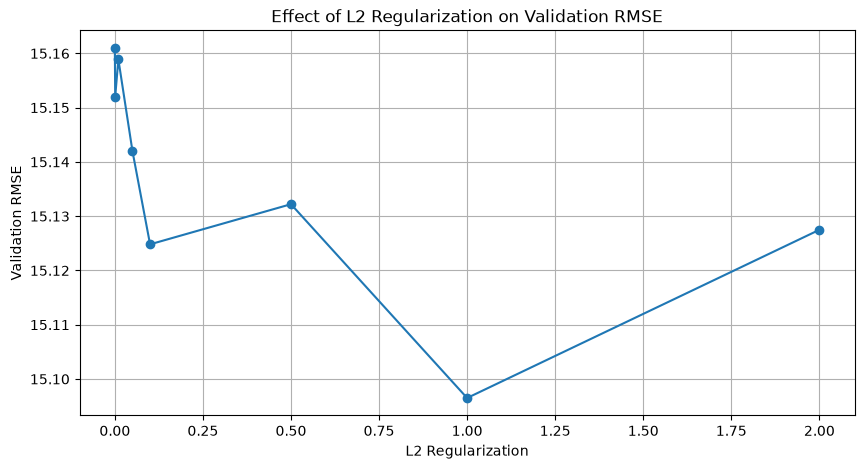

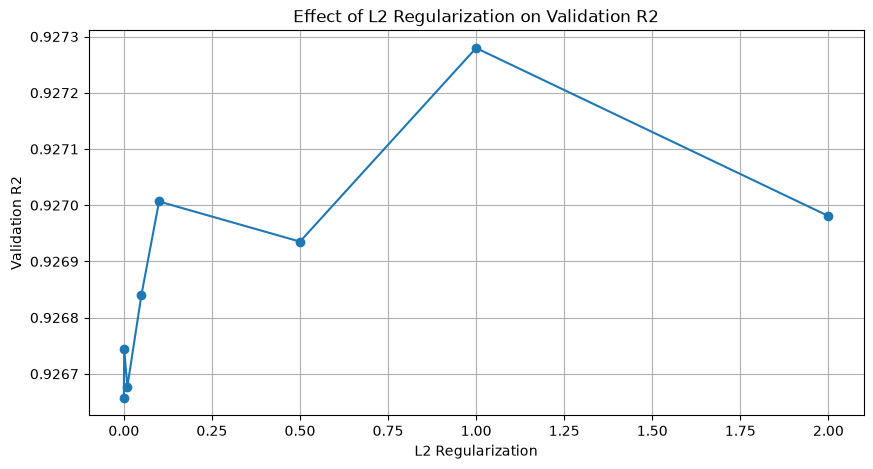

In [ ]:
# ============================================================
# CELL 19 — Visualize Regularization Results
# ============================================================

regularization_plot_df = regularization_df.sort_values("l2_regularization")

plt.figure(figsize=(10, 5))
plt.plot(
    regularization_plot_df["l2_regularization"],
    regularization_plot_df["val_RMSE"],
    marker="o"
)
plt.title("Effect of L2 Regularization on Validation RMSE")
plt.xlabel("L2 Regularization")
plt.ylabel("Validation RMSE")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    regularization_plot_df["l2_regularization"],
    regularization_plot_df["val_R2"],
    marker="o"
)
plt.title("Effect of L2 Regularization on Validation R2")
plt.xlabel("L2 Regularization")
plt.ylabel("Validation R2")
plt.grid(True)
plt.show()

## 9. Manual hyperparameter search

In [ ]:
# ============================================================
# CELL 20 — Manual Hyperparameter Search
# ============================================================

param_candidates = []

learning_rates = [0.02, 0.03, 0.04, 0.05, 0.08]
max_leaf_nodes_list = [10, 15, 31, 45, 63]
max_iter_list = [400, 700, 900]
l2_list = [0.0, 0.01, 0.05, 0.1, 0.5]

for lr in learning_rates:
    for leaves in max_leaf_nodes_list:
        for max_iter in max_iter_list:
            for l2 in l2_list:
                param_candidates.append({
                    "learning_rate": lr,
                    "max_leaf_nodes": leaves,
                    "max_iter": max_iter,
                    "l2_regularization": l2
                })

np.random.seed(RANDOM_STATE)
sample_size = min(25, len(param_candidates))
sampled_indices = np.random.choice(len(param_candidates), size=sample_size, replace=False)
sampled_params = [param_candidates[i] for i in sampled_indices]

manual_search_results = []
manual_search_pipelines = {}

for i, params in enumerate(sampled_params, start=1):
    print("=" * 70)
    print(f"Trial {i}/{sample_size}")
    print(params)

    model = HistGradientBoostingRegressor(
        **params,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=25,
        random_state=RANDOM_STATE
    )

    pipeline, result = train_evaluate_pipeline(f"HGB_manual_{i}", model)
    result.update(params)

    manual_search_results.append(result)
    manual_search_pipelines[result["model"]] = pipeline

manual_search_df = pd.DataFrame(manual_search_results).sort_values(by="val_RMSE")

display(manual_search_df.head(10))

Trial 1/25
{'learning_rate': 0.04, 'max_leaf_nodes': 15, 'max_iter': 400, 'l2_regularization': 0.05}
Trial 2/25
{'learning_rate': 0.02, 'max_leaf_nodes': 31, 'max_iter': 400, 'l2_regularization': 0.1}
Trial 3/25
{'learning_rate': 0.02, 'max_leaf_nodes': 15, 'max_iter': 400, 'l2_regularization': 0.0}
Trial 4/25
{'learning_rate': 0.08, 'max_leaf_nodes': 15, 'max_iter': 400, 'l2_regularization': 0.01}
Trial 5/25
{'learning_rate': 0.02, 'max_leaf_nodes': 45, 'max_iter': 900, 'l2_regularization': 0.05}
Trial 6/25
{'learning_rate': 0.05, 'max_leaf_nodes': 63, 'max_iter': 700, 'l2_regularization': 0.01}
Trial 7/25
{'learning_rate': 0.03, 'max_leaf_nodes': 10, 'max_iter': 400, 'l2_regularization': 0.01}
Trial 8/25
{'learning_rate': 0.03, 'max_leaf_nodes': 31, 'max_iter': 900, 'l2_regularization': 0.5}
Trial 9/25
{'learning_rate': 0.05, 'max_leaf_nodes': 45, 'max_iter': 900, 'l2_regularization': 0.0}
Trial 10/25
{'learning_rate': 0.03, 'max_leaf_nodes': 45, 'max_iter': 700, 'l2_regularization':

,model,train_MAE,train_RMSE,train_SMAPE,train_R2,val_MAE,val_RMSE,val_SMAPE,val_R2,learning_rate,max_leaf_nodes,max_iter,l2_regularization
1,HGB_manual_2,10.892899,14.577425,11.742773,0.932784,11.135797,14.996273,11.923530,0.928242,0.02,31,400,0.10
22,HGB_manual_23,9.737984,12.821130,10.790579,0.948005,11.131313,15.015292,11.854055,0.928060,0.02,63,900,0.05
21,HGB_manual_22,10.490569,13.934360,11.417539,0.938584,11.134340,15.031303,11.872446,0.927906,0.04,31,400,0.01
13,HGB_manual_14,10.111765,13.357155,11.111429,0.943567,11.145841,15.039818,11.882634,0.927825,0.02,45,900,0.00
11,HGB_manual_12,10.582086,14.079827,11.484306,0.937295,11.148035,15.042081,11.887638,0.927803,0.02,31,700,0.50
9,HGB_manual_10,9.972894,13.153737,10.997877,0.945272,11.143671,15.047799,11.879308,0.927748,0.03,45,700,0.01
19,HGB_manual_20,10.631061,14.155028,11.522445,0.936623,11.149340,15.059410,11.891996,0.927637,0.03,15,900,0.01
0,HGB_manual_1,10.907173,14.597035,11.758184,0.932603,11.173293,15.070556,11.947777,0.927529,0.04,15,400,0.05
4,HGB_manual_5,10.105743,13.346357,11.106376,0.943658,11.167408,15.073986,11.893542,0.927496,0.02,45,900,0.05
12,HGB_manual_13,10.013229,13.205875,11.036966,0.944838,11.168120,15.079376,11.891722,0.927445,0.05,45,400,0.50


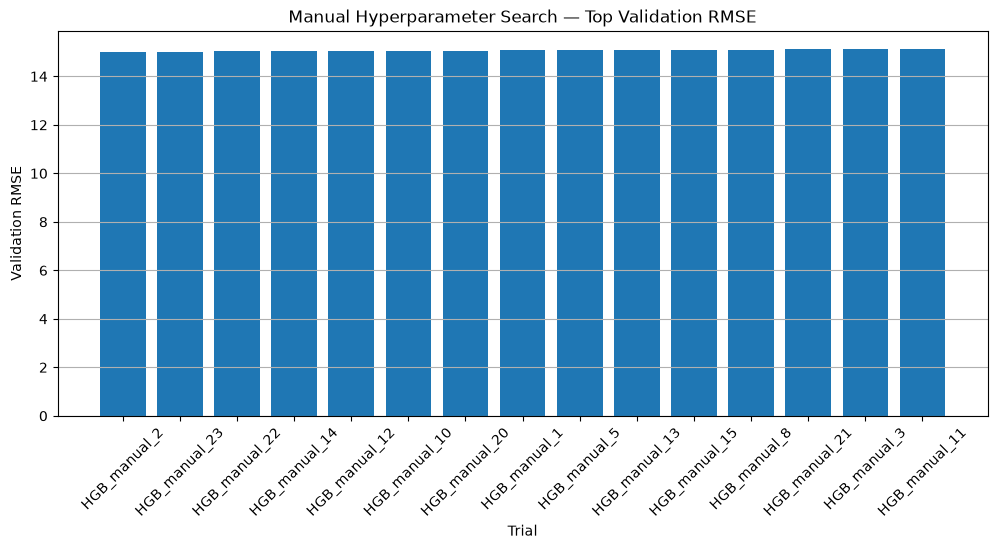

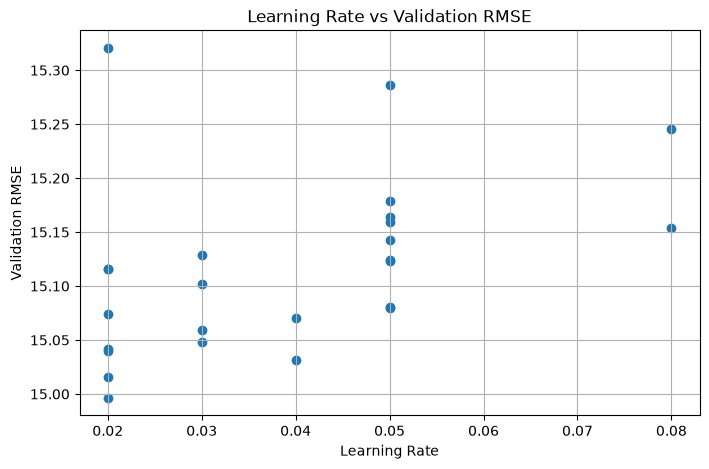

In [ ]:
# ============================================================
# CELL 21 — Visualize Manual Search
# ============================================================

top_manual = manual_search_df.head(15).copy()

plt.figure(figsize=(12, 5))
plt.bar(top_manual["model"], top_manual["val_RMSE"])
plt.title("Manual Hyperparameter Search — Top Validation RMSE")
plt.xlabel("Trial")
plt.ylabel("Validation RMSE")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(manual_search_df["learning_rate"], manual_search_df["val_RMSE"])
plt.title("Learning Rate vs Validation RMSE")
plt.xlabel("Learning Rate")
plt.ylabel("Validation RMSE")
plt.grid(True)
plt.show()

## 10. QPSO-inspired optimization

In [ ]:
# ============================================================
# CELL 22 — QPSO Helper Functions
# ============================================================

def vector_to_hgb_params(vector):
    learning_rate = float(vector[0])
    max_leaf_nodes = int(round(vector[1]))
    max_iter = int(round(vector[2]))
    l2_regularization = float(vector[3])

    learning_rate = float(np.clip(learning_rate, 0.01, 0.12))
    max_leaf_nodes = int(np.clip(max_leaf_nodes, 10, 80))
    max_iter = int(np.clip(max_iter, 300, 1000))
    l2_regularization = float(np.clip(l2_regularization, 0.0, 2.0))

    return {
        "learning_rate": learning_rate,
        "max_leaf_nodes": max_leaf_nodes,
        "max_iter": max_iter,
        "l2_regularization": l2_regularization
    }


def evaluate_hgb_params(params):
    model = HistGradientBoostingRegressor(
        **params,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=RANDOM_STATE
    )

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)
    val_pred = pipeline.predict(X_val)

    val_mae, val_rmse, val_smape, val_r2 = evaluate_predictions(y_val, val_pred)

    return val_mae, val_rmse, val_smape, val_r2, pipeline

In [ ]:
# ============================================================
# CELL 23 — QPSO-Inspired Hyperparameter Optimization
# ============================================================

lower_bounds = np.array([0.01, 10, 300, 0.0])
upper_bounds = np.array([0.12, 80, 1000, 2.0])

num_particles = 8
num_iterations = 8
beta = 0.75

np.random.seed(RANDOM_STATE)

particles = lower_bounds + np.random.rand(num_particles, 4) * (upper_bounds - lower_bounds)

personal_best_positions = particles.copy()
personal_best_scores = np.full(num_particles, np.inf)

global_best_position = None
global_best_score = np.inf
global_best_mae = None
global_best_smape = None
global_best_r2 = None
global_best_pipeline = None

qpso_history = []

for iteration in range(1, num_iterations + 1):
    print("=" * 70)
    print(f"QPSO Iteration {iteration}/{num_iterations}")

    mean_best = personal_best_positions.mean(axis=0)

    for i in range(num_particles):
        params = vector_to_hgb_params(particles[i])

        val_mae, val_rmse, val_smape, val_r2, pipeline = evaluate_hgb_params(params)

        if val_rmse < personal_best_scores[i]:
            personal_best_scores[i] = val_rmse
            personal_best_positions[i] = particles[i].copy()

        if val_rmse < global_best_score:
            global_best_score = val_rmse
            global_best_position = particles[i].copy()
            global_best_mae = val_mae
            global_best_smape = val_smape
            global_best_r2 = val_r2
            global_best_pipeline = pipeline

        qpso_history.append({
            "iteration": iteration,
            "particle": i,
            "val_MAE": val_mae,
            "val_RMSE": val_rmse,
            "val_SMAPE": val_smape,
            "val_R2": val_r2,
            **params
        })

        print(f"Particle {i} | RMSE: {val_rmse:.4f} | R2: {val_r2:.4f} | Params: {params}")

    for i in range(num_particles):
        phi = np.random.rand(4)
        p = phi * personal_best_positions[i] + (1 - phi) * global_best_position

        u = np.random.rand(4)
        direction = np.where(np.random.rand(4) < 0.5, 1, -1)

        particles[i] = p + direction * beta * np.abs(mean_best - particles[i]) * np.log(1 / u)
        particles[i] = np.clip(particles[i], lower_bounds, upper_bounds)

qpso_results_df = pd.DataFrame(qpso_history).sort_values(by="val_RMSE")

best_qpso_params = vector_to_hgb_params(global_best_position)

print("=" * 70)
print("Best QPSO Parameters:")
print(best_qpso_params)
print("Best QPSO Validation MAE:", global_best_mae)
print("Best QPSO Validation RMSE:", global_best_score)
print("Best QPSO Validation SMAPE:", global_best_smape)
print("Best QPSO Validation R2:", global_best_r2)

display(qpso_results_df.head(10))

QPSO Iteration 1/8
Particle 0 | RMSE: 15.2158 | R2: 0.9261 | Params: {'learning_rate': 0.051199413073209875, 'max_leaf_nodes': 77, 'max_iter': 812, 'l2_regularization': 1.1973169683940732}
Particle 1 | RMSE: 15.0143 | R2: 0.9281 | Params: {'learning_rate': 0.02716205044866802, 'max_leaf_nodes': 21, 'max_iter': 341, 'l2_regularization': 1.7323522915498704}
Particle 2 | RMSE: 15.1417 | R2: 0.9268 | Params: {'learning_rate': 0.07612265129175297, 'max_leaf_nodes': 60, 'max_iter': 314, 'l2_regularization': 1.9398197043239886}
Particle 3 | RMSE: 15.2850 | R2: 0.9255 | Params: {'learning_rate': 0.10156869048804638, 'max_leaf_nodes': 25, 'max_iter': 427, 'l2_regularization': 0.36680901970686763}
Particle 4 | RMSE: 15.1050 | R2: 0.9272 | Params: {'learning_rate': 0.04346664672554915, 'max_leaf_nodes': 47, 'max_iter': 602, 'l2_regularization': 0.5824582803960838}
Particle 5 | RMSE: 15.1468 | R2: 0.9268 | Params: {'learning_rate': 0.07730381841946174, 'max_leaf_nodes': 20, 'max_iter': 505, 'l2_re

,iteration,particle,val_MAE,val_RMSE,val_SMAPE,val_R2,learning_rate,max_leaf_nodes,max_iter,l2_regularization
47,6,7,11.112238,14.971110,11.890053,0.928483,0.020860,28,477,1.370806
37,5,5,11.117266,14.978161,11.897349,0.928415,0.014913,40,470,1.539394
62,8,6,11.116892,14.980479,11.893358,0.928393,0.019273,28,502,1.429508
24,4,0,11.111591,14.981427,11.872923,0.928384,0.015833,39,632,1.292047
33,5,1,11.113409,14.992362,11.860327,0.928279,0.018032,41,649,1.772667
25,4,1,11.121446,14.993281,11.878228,0.928271,0.025350,40,389,0.908966
12,2,4,11.119705,14.994557,11.873163,0.928258,0.023230,42,447,1.521646
63,8,7,11.132473,14.995076,11.923095,0.928254,0.017959,28,487,1.378491
32,5,0,11.114238,14.998606,11.861593,0.928220,0.016773,40,716,1.255759
50,7,2,11.127295,15.006073,11.877113,0.928148,0.028100,31,489,1.355856


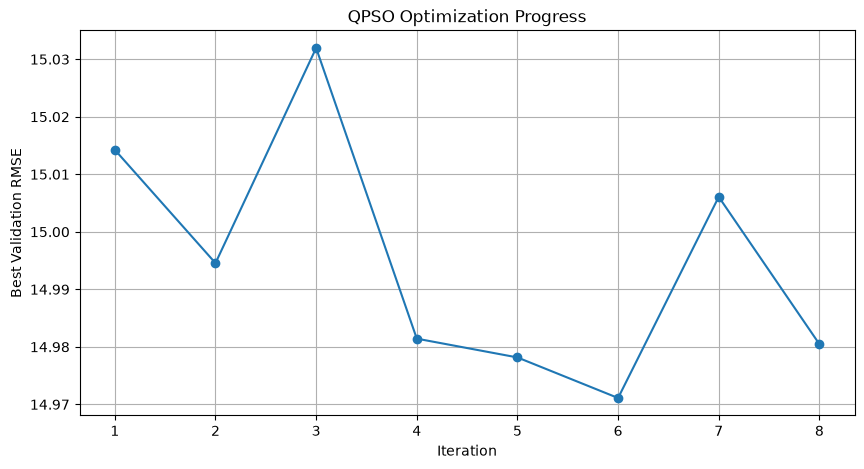

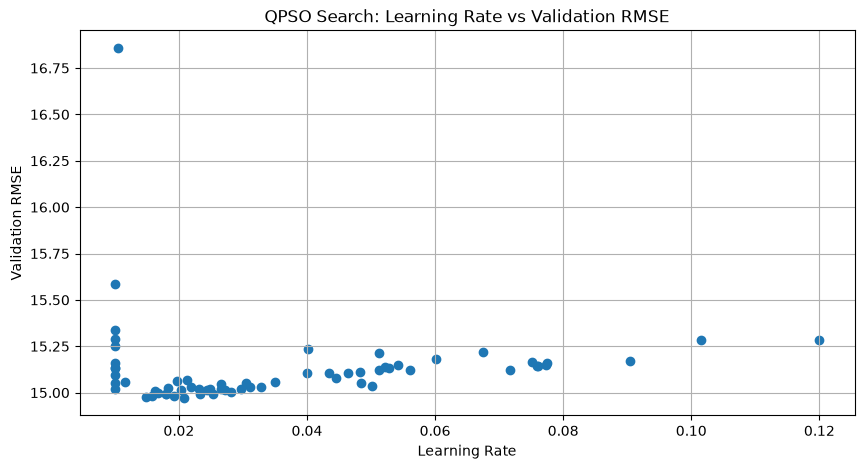

In [ ]:
# ============================================================
# CELL 24 — Visualize QPSO Optimization Progress
# ============================================================

qpso_progress = (
    pd.DataFrame(qpso_history)
    .groupby("iteration")["val_RMSE"]
    .min()
    .reset_index()
)

plt.figure(figsize=(10, 5))
plt.plot(qpso_progress["iteration"], qpso_progress["val_RMSE"], marker="o")
plt.title("QPSO Optimization Progress")
plt.xlabel("Iteration")
plt.ylabel("Best Validation RMSE")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(qpso_results_df["learning_rate"], qpso_results_df["val_RMSE"])
plt.title("QPSO Search: Learning Rate vs Validation RMSE")
plt.xlabel("Learning Rate")
plt.ylabel("Validation RMSE")
plt.grid(True)
plt.show()

## 11. Select best model using validation set

In [ ]:
# ============================================================
# CELL 25 — Combine Validation Results
# ============================================================

baseline_compare = baseline_results_df[["model", "val_MAE", "val_RMSE", "val_SMAPE", "val_R2"]].copy()
baseline_compare["source"] = "baseline"

regularization_compare = regularization_df[["model", "val_MAE", "val_RMSE", "val_SMAPE", "val_R2"]].copy()
regularization_compare["source"] = "regularization"

manual_compare = manual_search_df[["model", "val_MAE", "val_RMSE", "val_SMAPE", "val_R2"]].copy()
manual_compare["source"] = "manual_search"

qpso_compare = qpso_results_df[["val_MAE", "val_RMSE", "val_SMAPE", "val_R2"]].copy()
qpso_compare["model"] = "QPSO_HGB"
qpso_compare["source"] = "qpso"
qpso_compare = qpso_compare[["model", "val_MAE", "val_RMSE", "val_SMAPE", "val_R2", "source"]]

all_validation_results = pd.concat(
    [baseline_compare, regularization_compare, manual_compare, qpso_compare],
    ignore_index=True
).sort_values(by="val_RMSE")

display(all_validation_results.head(20))

,model,val_MAE,val_RMSE,val_SMAPE,val_R2,source
41,QPSO_HGB,11.112238,14.971110,11.890053,0.928483,qpso
42,QPSO_HGB,11.117266,14.978161,11.897349,0.928415,qpso
43,QPSO_HGB,11.116892,14.980479,11.893358,0.928393,qpso
44,QPSO_HGB,11.111591,14.981427,11.872923,0.928384,qpso
45,QPSO_HGB,11.113409,14.992362,11.860327,0.928279,qpso
46,QPSO_HGB,11.121446,14.993281,11.878228,0.928271,qpso
47,QPSO_HGB,11.119705,14.994557,11.873163,0.928258,qpso
48,QPSO_HGB,11.132473,14.995076,11.923095,0.928254,qpso
16,HGB_manual_2,11.135797,14.996273,11.923530,0.928242,manual_search
49,QPSO_HGB,11.114238,14.998606,11.861593,0.928220,qpso


In [ ]:
# ============================================================
# CELL 26 — Choose Best Final Candidate
# ============================================================

best_source = all_validation_results.iloc[0]["source"]
best_candidate_name = all_validation_results.iloc[0]["model"]

print("Best source:", best_source)
print("Best candidate:", best_candidate_name)

if best_source == "baseline":
    best_model = baseline_pipelines[best_candidate_name]

elif best_source == "regularization":
    best_model = regularization_pipelines[best_candidate_name]

elif best_source == "manual_search":
    best_model = manual_search_pipelines[best_candidate_name]

else:
    best_candidate_name = "QPSO_HGB"
    best_model = global_best_pipeline

print("Selected best validation model:", best_candidate_name)

Best source: qpso
Best candidate: QPSO_HGB
Selected best validation model: QPSO_HGB


## 12. Final test evaluation

In [ ]:
# ============================================================
# CELL 27 — Final Test Evaluation
# ============================================================

train_predictions = best_model.predict(X_train)
val_predictions = best_model.predict(X_val)
test_predictions = best_model.predict(X_test)

train_mae, train_rmse, train_smape, train_r2 = evaluate_predictions(y_train, train_predictions)
val_mae, val_rmse, val_smape, val_r2 = evaluate_predictions(y_val, val_predictions)
test_mae, test_rmse, test_smape, test_r2 = evaluate_predictions(y_test, test_predictions)

print("=" * 70)
print("FINAL NORMAL 3-HOUR AHEAD FORECASTING RESULTS")
print("=" * 70)

print("Selected Model:", best_candidate_name)

results_df = pd.DataFrame([
    {"label": "train", "MAE": train_mae, "RMSE": train_rmse, "SMAPE": train_smape, "R2": train_r2},
    {"label": "validation", "MAE": val_mae, "RMSE": val_rmse, "SMAPE": val_smape, "R2": val_r2},
    {"label": "test", "MAE": test_mae, "RMSE": test_rmse, "SMAPE": test_smape, "R2": test_r2},
])

display(results_df)

FINAL NORMAL 3-HOUR AHEAD FORECASTING RESULTS
Selected Model: QPSO_HGB


,label,MAE,RMSE,SMAPE,R2
0,train,10.820280,14.465376,11.672495,0.933814
1,validation,11.112238,14.971110,11.890053,0.928483
2,test,12.799289,17.556777,12.347266,0.910233


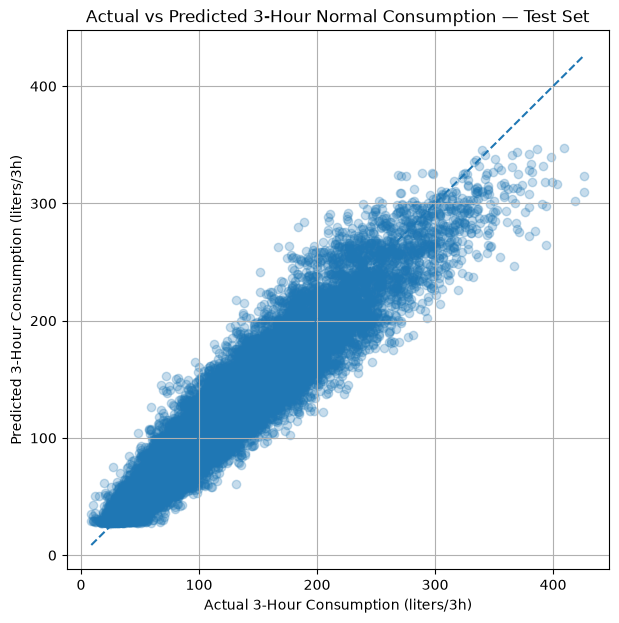

In [ ]:
# ============================================================
# CELL 28 — Actual vs Predicted on Test Set
# ============================================================

plt.figure(figsize=(7, 7))
plt.scatter(y_test, test_predictions, alpha=0.25)

min_value = min(y_test.min(), test_predictions.min())
max_value = max(y_test.max(), test_predictions.max())

plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.title("Actual vs Predicted 3-Hour Normal Consumption — Test Set")
plt.xlabel("Actual 3-Hour Consumption (liters/3h)")
plt.ylabel("Predicted 3-Hour Consumption (liters/3h)")
plt.grid(True)
plt.show()

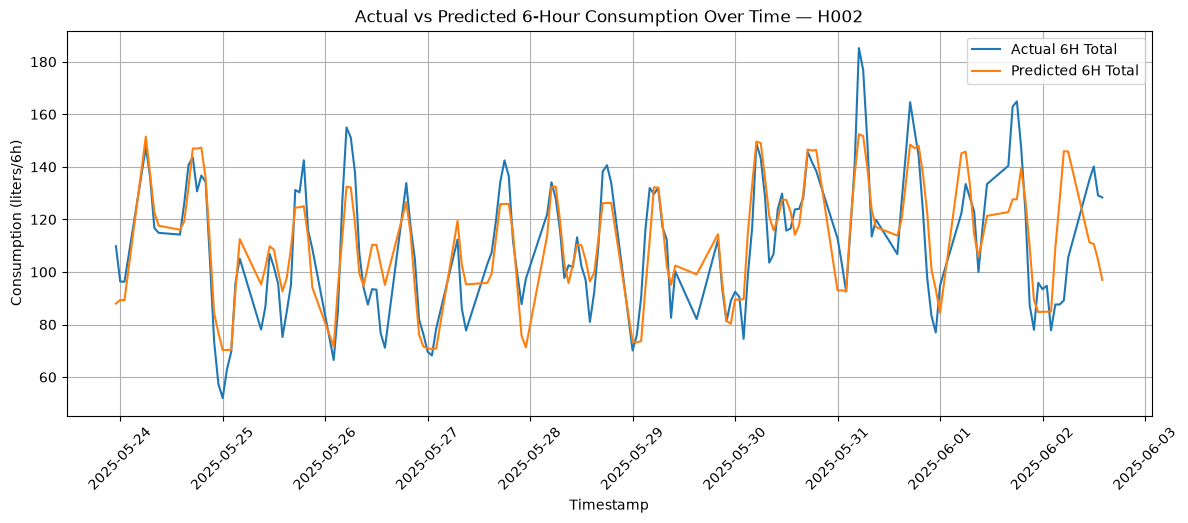

In [ ]:
# ============================================================
# CELL 30 — Time-Series Prediction Visualization
# ============================================================

sample_household = test_df["household_id"].iloc[0]

sample_test = test_df[test_df["household_id"] == sample_household].copy()
sample_test["predicted_6h_consumption"] = best_model.predict(sample_test[candidate_features])

sample_plot = sample_test.head(24 * 7)

plt.figure(figsize=(14, 5))
plt.plot(sample_plot["timestamp"], sample_plot[target], label="Actual 6H Total")
plt.plot(sample_plot["timestamp"], sample_plot["predicted_6h_consumption"], label="Predicted 6H Total")

plt.title(f"Actual vs Predicted 6-Hour Consumption Over Time — {sample_household}")
plt.xlabel("Timestamp")
plt.ylabel("Consumption (liters/6h)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

## 13. Feature importance

In [ ]:
# ============================================================
# CELL 31 — Permutation Feature Importance
# ============================================================

sample_size = min(10000, len(X_test))

X_test_sample = X_test.sample(n=sample_size, random_state=RANDOM_STATE)
y_test_sample = y_test.loc[X_test_sample.index]

perm_result = permutation_importance(
    best_model,
    X_test_sample,
    y_test_sample,
    n_repeats=3,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": candidate_features,
    "importance": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values(by="importance", ascending=False)

display(importance_df.head(20))

,feature,importance,importance_std
40,rolling_mean_168h,45.282158,0.169497
1,hour_cos,13.907168,0.194721
7,is_weekend,2.884184,0.074267
0,hour_sin,2.356616,0.061762
13,num_of_tanks,1.687697,0.026698
11,behavior_profile,0.725879,0.013766
9,number_of_users,0.467973,0.039385
46,rolling_std_168h,0.356273,0.039133
15,water_level,0.178209,0.015732
37,rolling_mean_12h,0.156969,0.006405


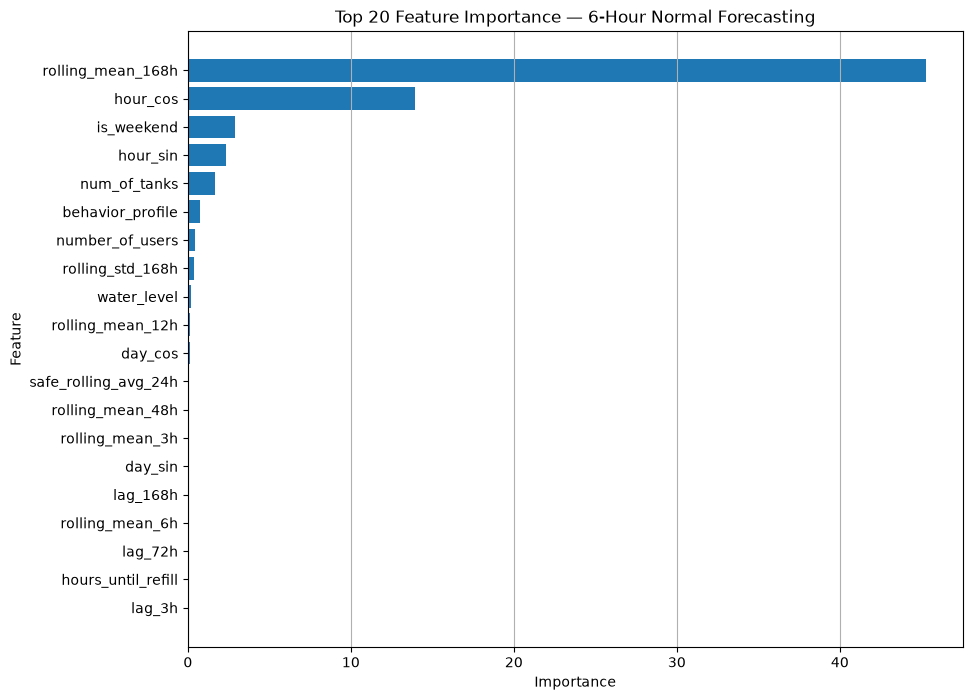

In [ ]:
# ============================================================
# CELL 32 — Visualize Feature Importance
# ============================================================

top_n = 20

top_importance = (
    importance_df
    .head(top_n)
    .sort_values(by="importance")
)

plt.figure(figsize=(10, 8))
plt.barh(top_importance["feature"], top_importance["importance"])
plt.title(f"Top {top_n} Feature Importance — 6-Hour Normal Forecasting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x")
plt.show()

## 14. Apply 6-hour expected normal forecast to all records

In [ ]:
# ============================================================
# CELL 33 — Apply Expected 3H Normal Forecast to All Records
# ============================================================

df_all_records = df_all_records.sort_values(["household_id", "timestamp"]).reset_index(drop=True)

# Create all features for all records
df_all_records["day_of_week_num"] = df_all_records["timestamp"].dt.dayofweek
df_all_records["day"] = df_all_records["timestamp"].dt.day
df_all_records["week_of_year"] = df_all_records["timestamp"].dt.isocalendar().week.astype(int)

df_all_records["hour_sin"] = np.sin(2 * np.pi * df_all_records["hour"] / 24)
df_all_records["hour_cos"] = np.cos(2 * np.pi * df_all_records["hour"] / 24)

df_all_records["day_sin"] = np.sin(2 * np.pi * df_all_records["day_of_week_num"] / 7)
df_all_records["day_cos"] = np.cos(2 * np.pi * df_all_records["day_of_week_num"] / 7)

df_all_records["hour_index_per_household"] = (
    df_all_records.groupby("household_id").cumcount()
)

df_all_records["hours_since_refill"] = df_all_records["hour_index_per_household"] % (7 * 24)
df_all_records["hours_until_refill"] = ((7 * 24) - df_all_records["hours_since_refill"]) % (7 * 24)
df_all_records["days_since_refill"] = (df_all_records["hours_since_refill"] // 24).astype(int)
df_all_records["refill_position"] = df_all_records["hours_since_refill"] / (7 * 24 - 1)
df_all_records["is_refill_day"] = (df_all_records["days_since_refill"] == 0).astype(int)
df_all_records["refill_sin"] = np.sin(2 * np.pi * df_all_records["hours_since_refill"] / (7 * 24))
df_all_records["refill_cos"] = np.cos(2 * np.pi * df_all_records["hours_since_refill"] / (7 * 24))

df_all_records["safe_previous_consumption"] = (
    df_all_records.groupby("household_id")["actual_consumption"].shift(1)
)

df_all_records["safe_rolling_avg_7h"] = (
    df_all_records.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).mean())
)

df_all_records["safe_rolling_avg_24h"] = (
    df_all_records.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=24, min_periods=1).mean())
)

for lag in lag_hours:
    df_all_records[f"lag_{lag}h"] = (
        df_all_records.groupby("household_id")["actual_consumption"].shift(lag)
    )

for window in rolling_windows:
    df_all_records[f"rolling_mean_{window}h"] = (
        df_all_records.groupby("household_id")["actual_consumption"]
        .transform(lambda s: s.shift(1).rolling(window=window, min_periods=1).mean())
    )

    df_all_records[f"rolling_std_{window}h"] = (
        df_all_records.groupby("household_id")["actual_consumption"]
        .transform(lambda s: s.shift(1).rolling(window=window, min_periods=2).std())
    )

df_all_records["rolling_sum_6h"] = (
    df_all_records.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=6, min_periods=1).sum())
)

df_all_records["rolling_sum_12h"] = (
    df_all_records.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=12, min_periods=1).sum())
)

df_all_records["rolling_sum_24h"] = (
    df_all_records.groupby("household_id")["actual_consumption"]
    .transform(lambda s: s.shift(1).rolling(window=24, min_periods=1).sum())
)

for col in historical_cols:
    df_all_records[col] = df_all_records[col].fillna(df_all_records[col].median())

df_all_records["expected_next_3h_normal_consumption"] = best_model.predict(df_all_records[candidate_features])

display(df_all_records[[
    "household_id",
    "timestamp",
    "anomaly_type",
    "actual_consumption",
    "expected_next_3h_normal_consumption"
]].head())

,household_id,timestamp,anomaly_type,actual_consumption,expected_next_3h_normal_consumption
0,H001,2025-01-01 00:00:00,normal,17.38,55.573535
1,H001,2025-01-01 01:00:00,normal,14.57,33.057381
2,H001,2025-01-01 02:00:00,normal,13.12,34.708704
3,H001,2025-01-01 03:00:00,normal,20.05,43.652720
4,H001,2025-01-01 04:00:00,normal,10.26,61.964112


## 15. Save final artifacts

In [ ]:
# ============================================================
# CELL 34 — Save Model and Reports
# ============================================================

os.makedirs("../models", exist_ok=True)
os.makedirs("../processed_data", exist_ok=True)
os.makedirs("../reports", exist_ok=True)

joblib.dump(best_model, "../models/normal_3h_consumption_forecasting_model.pkl")

df.to_csv("../processed_data/normal_3h_consumption_training_data_with_predictions.csv", index=False)

df_all_records.to_csv(
    "../processed_data/master_dataset_with_expected_next_3h_normal_consumption.csv",
    index=False
)

all_validation_results.to_csv(
    "../reports/normal_3h_forecasting_validation_results.csv",
    index=False
)

importance_df.to_csv(
    "../reports/normal_3h_forecasting_feature_importance.csv",
    index=False
)

final_metrics = pd.DataFrame([{
    "selected_model": best_candidate_name,
    "train_MAE": train_mae,
    "train_RMSE": train_rmse,
    "train_SMAPE": train_smape,
    "train_R2": train_r2,
    "val_MAE": val_mae,
    "val_RMSE": val_rmse,
    "val_SMAPE": val_smape,
    "val_R2": val_r2,
    "test_MAE": test_mae,
    "test_RMSE": test_rmse,
    "test_SMAPE": test_smape,
    "test_R2": test_r2
}])

final_metrics.to_csv(
    "../reports/normal_3h_forecasting_final_metrics.csv",
    index=False
)

print("Saved successfully:")
print("- ../models/normal_3h_consumption_forecasting_model.pkl")
print("- ../processed_data/normal_3h_consumption_training_data_with_predictions.csv")
print("- ../processed_data/master_dataset_with_expected_next_3h_normal_consumption.csv")
print("- ../reports/normal_3h_forecasting_validation_results.csv")
print("- ../reports/normal_3h_forecasting_feature_importance.csv")
print("- ../reports/normal_3h_forecasting_final_metrics.csv")

Saved successfully:
- ../models/normal_3h_consumption_forecasting_model.pkl
- ../processed_data/normal_3h_consumption_training_data_with_predictions.csv
- ../processed_data/master_dataset_with_expected_next_3h_normal_consumption.csv
- ../reports/normal_3h_forecasting_validation_results.csv
- ../reports/normal_3h_forecasting_feature_importance.csv
- ../reports/normal_3h_forecasting_final_metrics.csv


In [ ]:
# ============================================================
# CELL 35 — Final Notebook Summary
# ============================================================

print("=" * 80)
print("NORMAL 3-HOUR AHEAD CONSUMPTION FORECASTING MODEL SUMMARY")
print("=" * 80)

print("\nTask Type:")
print("Regression")

print("\nTarget:")
print("expected next 3-hour normal total consumption in liters/3h")

print("\nTraining Data:")
print("Only records where current and next 3 hours are normal")

print("\nData Split:")
print("Train: 60% | Validation: 20% | Test: 20%")

print("\nSelected Model:")
print(best_candidate_name)

print("\nFinal Metrics:")
display(results_df)

print("\nTop 10 Important Features:")
display(importance_df.head(10))

print("\nSaved Outputs:")
print("- Normal 3-hour forecasting model")
print("- Normal 3-hour training dataset with predictions")
print("- Full master dataset with expected next 3-hour normal consumption")
print("- Validation results")
print("- Feature importance")
print("- Final metrics")

NORMAL 3-HOUR AHEAD CONSUMPTION FORECASTING MODEL SUMMARY

Task Type:
Regression

Target:
expected next 3-hour normal total consumption in liters/3h

Training Data:
Only records where current and next 3 hours are normal

Data Split:
Train: 60% | Validation: 20% | Test: 20%

Selected Model:
QPSO_HGB

Final Metrics:


,label,MAE,RMSE,SMAPE,R2
0,train,10.820280,14.465376,11.672495,0.933814
1,validation,11.112238,14.971110,11.890053,0.928483
2,test,12.799289,17.556777,12.347266,0.910233



Top 10 Important Features:


,feature,importance,importance_std
40,rolling_mean_168h,45.282158,0.169497
1,hour_cos,13.907168,0.194721
7,is_weekend,2.884184,0.074267
0,hour_sin,2.356616,0.061762
13,num_of_tanks,1.687697,0.026698
11,behavior_profile,0.725879,0.013766
9,number_of_users,0.467973,0.039385
46,rolling_std_168h,0.356273,0.039133
15,water_level,0.178209,0.015732
37,rolling_mean_12h,0.156969,0.006405



Saved Outputs:
- Normal 3-hour forecasting model
- Normal 3-hour training dataset with predictions
- Full master dataset with expected next 3-hour normal consumption
- Validation results
- Feature importance
- Final metrics
